# Module 4: Classical ML Training & Evaluation

## 4.1 · Training configuration

In [ ]:
PROJECT_DIR = "CounterShield"
DATASETS = ["bot_iot", "cic_ids2017", "unsw_nb15"]
SEED = 42
TARGET = "y_binary"

DEV_TRAIN_CAP    = 300_000
FINAL_TRAIN_CAP  = 1_000_000
SELECTION_METRIC = "f1_macro"
FORCE_RETRAIN    = False

MODELS = {
    "logreg":        {"C": 1.0, "max_iter": 2000, "solver": "lbfgs", "class_weight": "balanced"},
    "random_forest": {"n_estimators": 150, "max_features": "sqrt", "min_samples_leaf": 1, "class_weight": "balanced_subsample"},
    "hist_gb":       {"max_iter": 300, "learning_rate": 0.1, "max_leaf_nodes": 63, "early_stopping": True,
                      "validation_fraction": 0.1, "n_iter_no_change": 20, "class_weight": "balanced"},
    "mlp":           {"hidden_layer_sizes": (128, 64), "activation": "relu", "alpha": 1e-4, "batch_size": 1024,
                      "learning_rate_init": 1e-3, "max_iter": 40, "early_stopping": True, "n_iter_no_change": 5},
}

### Setup

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
import sys, warnings, platform, datetime as dt
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)
try:
    from IPython.display import display
except ImportError:
    display = print

import os, gc, json, time, hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import joblib, sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, roc_auc_score, average_precision_score, confusion_matrix)

def sha256_file(path, block=8 * 1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(block), b""):
            h.update(chunk)
    return h.hexdigest()

def make_model(name, params, seed):
    p = dict(params)
    if name == "logreg":
        return LogisticRegression(random_state=seed, **p)
    if name == "random_forest":
        return RandomForestClassifier(random_state=seed, n_jobs=-1, **p)
    if name == "hist_gb":
        return HistGradientBoostingClassifier(random_state=seed, **p)
    if name == "mlp":
        return MLPClassifier(random_state=seed, **p)
    raise ValueError(name)

def _strat(y):
    y = pd.Series(y).astype(str); vc = y.value_counts()
    return y.where(~y.isin(vc.index[vc < 4]), "__rare__").to_numpy()

def load_split(base, m3, key, split, cap=None, seed=42):
    info = m3["datasets"][key]
    feats = info["feature_names"]
    d = pd.read_parquet(base / info["files"][split]["path"], columns=feats + ["y_binary", "y_class", "row"])
    if cap and len(d) > cap:
        keep, _ = train_test_split(np.arange(len(d)), train_size=cap, stratify=_strat(d["y_class"]), random_state=seed)
        d = d.iloc[np.sort(keep)].reset_index(drop=True)
    X = d[feats].to_numpy(dtype=np.float32)
    return X, d["y_binary"].to_numpy().astype(int), d["y_class"].astype(str).to_numpy(), d["row"].to_numpy()

def binary_metrics(y, prob, thr=0.5):
    pred = (prob >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    both = len(np.unique(y)) == 2
    return {
        "threshold": thr,
        "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "precision_attack": precision_score(y, pred, zero_division=0),
        "recall_attack": recall_score(y, pred, zero_division=0),
        "f1_attack": f1_score(y, pred, zero_division=0),
        "f1_macro": f1_score(y, pred, average="macro", zero_division=0),
        "mcc": matthews_corrcoef(y, pred),
        "roc_auc": roc_auc_score(y, prob) if both else np.nan,
        "pr_auc": average_precision_score(y, prob) if both else np.nan,
        "fpr": fp / max(fp + tn, 1), "fnr": fn / max(fn + tp, 1),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    }

def tune_threshold(y, prob, metric="f1_macro"):
    grid = np.unique(np.concatenate([np.linspace(0.01, 0.99, 99), np.quantile(prob, np.linspace(0.01, 0.99, 99))]))
    scores = [(t, binary_metrics(y, prob, t)[metric]) for t in grid]
    best = max(scores, key=lambda s: (s[1], -abs(s[0] - 0.5)))
    return float(best[0]), float(best[1])

def per_class_detection(y_class, y, prob, thr):
    pred = (prob >= thr).astype(int)
    df = pd.DataFrame({"y_class": y_class, "y": y, "pred": pred})
    g = df.groupby("y_class").agg(rows=("y", "size"), is_attack=("y", "max"), flagged=("pred", "mean")).reset_index()
    g["detection_rate"] = np.where(g.is_attack == 1, g.flagged, np.nan)
    g["false_alarm_rate"] = np.where(g.is_attack == 0, g.flagged, np.nan)
    return g.drop(columns="flagged")

def train_or_load(name, params, X, y, path, seed, force=False):
    if path.exists() and not force:
        obj = joblib.load(path)
        return obj["model"], obj["fit_seconds"], True
    model = make_model(name, params, seed)
    t0 = time.time(); model.fit(X, y); secs = time.time() - t0
    path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({"model": model, "fit_seconds": secs, "n_train": int(len(y)), "params": params,
                 "sklearn": sklearn.__version__}, path)
    return model, secs, False

def predict_proba1(model, X, chunk=500_000):
    return np.concatenate([model.predict_proba(X[i:i + chunk])[:, 1] for i in range(0, len(X), chunk)]).astype(np.float32)

BASE      = Path("/content/drive/MyDrive") / PROJECT_DIR
M3        = json.loads((BASE / "results" / "module3" / "module3_manifest.json").read_text())
MODEL_DIR = BASE / "models" / "module4"
RES       = BASE / "results" / "module4"
for p in (MODEL_DIR / "dev", MODEL_DIR / "final", RES / "val_probs", RES / "test_predictions", RES / "figures"):
    p.mkdir(parents=True, exist_ok=True)
(RES / "training_config.json").write_text(json.dumps({
    "datasets": DATASETS, "seed": SEED, "target": TARGET, "dev_train_cap": DEV_TRAIN_CAP, "final_train_cap": FINAL_TRAIN_CAP,
    "selection_metric": SELECTION_METRIC, "models": MODELS, "sklearn": sklearn.__version__,
    "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds")}, indent=2, default=str))
DEV, VAL, VALPROB, VALROWS = {}, {}, {}, {}

def run_model(name):
    rows = []
    for k in DATASETS:
        Xtr, ytr, _, _ = DEV[k]; Xva, yva, _, _ = VAL[k]
        model, secs, cached = train_or_load(name, MODELS[name], Xtr, ytr, MODEL_DIR / "dev" / f"{k}__{name}.joblib", SEED, FORCE_RETRAIN)
        t0 = time.time(); p = predict_proba1(model, Xva); ps = time.time() - t0
        VALPROB[(k, name)] = p; np.save(RES / "val_probs" / f"{k}__{name}.npy", p)
        m = binary_metrics(yva, p)
        m.update(dataset=k, model=name, fit_seconds=round(secs, 1), predict_seconds=round(ps, 1), n_train=int(len(ytr)), loaded_from_checkpoint=cached)
        VALROWS[(k, name)] = m; rows.append(m)
        print(f"{k:<12} {name:<14} fit {secs:8.1f}s{' (checkpoint)' if cached else '             '} | val F1-macro {m['f1_macro']:.4f} "
              f"| PR-AUC {m['pr_auc']:.4f} | FPR {m['fpr']:.4f} | FNR {m['fnr']:.4f}")
        del model; gc.collect()
    return pd.DataFrame(rows)
print("Module 3 manifest:", M3["created_utc"], "| sklearn", sklearn.__version__, "| CPUs", os.cpu_count())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Module 3 manifest: 2026-11-14T13:30:52+00:00 | sklearn 1.6.1 | CPUs 2


## 4.2 · Dataset & model readiness validation

In [ ]:
checks = []
def chk(k, name, ok, detail=""):
    checks.append({"dataset": k, "check": name, "passed": bool(ok), "detail": str(detail)})
for k in DATASETS:
    info = M3["datasets"][k]
    for s in ["train", "val", "test"]:
        f = BASE / info["files"][s]["path"]
        chk(k, f"{s} file present", f.exists(), info["files"][s]["path"])
        chk(k, f"{s} file unchanged since Module 3 (sha256)", f.exists() and sha256_file(f) == info["files"][s]["sha256"])
    DEV[k] = load_split(BASE, M3, k, "train", cap=DEV_TRAIN_CAP, seed=SEED)
    VAL[k] = load_split(BASE, M3, k, "val")
    for s, (X, y, c, r) in {"dev-train": DEV[k], "val": VAL[k]}.items():
        chk(k, f"{s}: finite float32 features", X.dtype == np.float32 and np.isfinite(X).all(), f"{X.shape[0]:,} x {X.shape[1]}")
        chk(k, f"{s}: both classes present", set(np.unique(y)) == {0, 1}, f"attack rate {y.mean():.3f}")
    chk(k, "feature count matches manifest", DEV[k][0].shape[1] == len(info["feature_names"]), len(info["feature_names"]))
for name, params in MODELS.items():
    try:
        make_model(name, params, SEED); chk("all", f"model '{name}' builds", True)
    except Exception as e:
        chk("all", f"model '{name}' builds", False, repr(e)[:120])
chk("all", "sklearn version matches Module 3", sklearn.__version__ == M3["sklearn"], f"now {sklearn.__version__}, M3 {M3['sklearn']}")
ready = pd.DataFrame(checks); ready.to_csv(RES / "readiness_checks.csv", index=False)
display(ready)
hard = ready[~ready.passed & ~ready.check.str.startswith("sklearn version")]
assert hard.empty, "readiness checks failed - see table"

,dataset,check,passed,detail
0,bot_iot,train file present,True,processed/model_ready/bot_iot/train.parquet
1,bot_iot,train file unchanged since Module 3 (sha256),True,
2,bot_iot,val file present,True,processed/model_ready/bot_iot/val.parquet
3,bot_iot,val file unchanged since Module 3 (sha256),True,
4,bot_iot,test file present,True,processed/model_ready/bot_iot/test.parquet
5,bot_iot,test file unchanged since Module 3 (sha256),True,
6,bot_iot,dev-train: finite float32 features,True,"300,000 x 46"
7,bot_iot,dev-train: both classes present,True,attack rate 0.990
8,bot_iot,val: finite float32 features,True,"135,589 x 46"
9,bot_iot,val: both classes present,True,attack rate 0.990


## 4.3 · Logistic Regression baseline

In [ ]:
res_logreg = run_model("logreg")

bot_iot      logreg         fit     37.0s (checkpoint) | val F1-macro 0.8957 | PR-AUC 1.0000 | FPR 0.0168 | FNR 0.0050
cic_ids2017  logreg         fit     97.3s              | val F1-macro 0.9566 | PR-AUC 0.9655 | FPR 0.0250 | FNR 0.0159
unsw_nb15    logreg         fit     25.9s              | val F1-macro 0.9061 | PR-AUC 0.9669 | FPR 0.1368 | FNR 0.0473


## 4.4 · Random Forest

In [ ]:
res_random_forest = run_model("random_forest")

bot_iot      random_forest  fit     66.7s (checkpoint) | val F1-macro 0.9974 | PR-AUC 1.0000 | FPR 0.0080 | FNR 0.0000
cic_ids2017  random_forest  fit    145.3s              | val F1-macro 0.9972 | PR-AUC 0.9997 | FPR 0.0005 | FNR 0.0068
unsw_nb15    random_forest  fit     28.3s              | val F1-macro 0.9333 | PR-AUC 0.9825 | FPR 0.0817 | FNR 0.0504


## 4.5 · HistGradientBoosting

In [ ]:
res_hist_gb = run_model("hist_gb")

bot_iot      hist_gb        fit     11.1s (checkpoint) | val F1-macro 0.9943 | PR-AUC 1.0000 | FPR 0.0080 | FNR 0.0001
cic_ids2017  hist_gb        fit     21.5s              | val F1-macro 0.9977 | PR-AUC 0.9999 | FPR 0.0010 | FNR 0.0021
unsw_nb15    hist_gb        fit     15.2s              | val F1-macro 0.9343 | PR-AUC 0.9832 | FPR 0.0748 | FNR 0.0556


## 4.6 · MLP baseline

In [ ]:
res_mlp = run_model("mlp")

bot_iot      mlp            fit     25.9s (checkpoint) | val F1-macro 0.9900 | PR-AUC 1.0000 | FPR 0.0299 | FNR 0.0001
cic_ids2017  mlp            fit     61.6s              | val F1-macro 0.9944 | PR-AUC 0.9988 | FPR 0.0018 | FNR 0.0093
unsw_nb15    mlp            fit     13.0s              | val F1-macro 0.9164 | PR-AUC 0.9738 | FPR 0.1013 | FNR 0.0644


## 4.7 · Validation metrics

In [ ]:
val_tab = pd.DataFrame(VALROWS.values())
cols = ["dataset", "model", "f1_macro", "f1_attack", "precision_attack", "recall_attack", "mcc", "roc_auc", "pr_auc",
        "balanced_accuracy", "accuracy", "fpr", "fnr", "tp", "fp", "tn", "fn", "fit_seconds", "predict_seconds", "n_train"]
val_tab = val_tab[cols].sort_values(["dataset", SELECTION_METRIC], ascending=[True, False])
val_tab.to_csv(RES / "validation_metrics.csv", index=False)
display(val_tab.style.format({c: "{:.4f}" for c in cols[2:13]}).hide(axis="index"))

dataset,model,f1_macro,f1_attack,precision_attack,recall_attack,mcc,roc_auc,pr_auc,balanced_accuracy,accuracy,fpr,fnr,tp,fp,tn,fn,fit_seconds,predict_seconds,n_train
bot_iot,random_forest,0.9974,0.9999,0.9999,1.0000,0.9948,1.0000,1.0000,0.9960,0.9999,0.0080,0.0000,134215,11,1360,3,66.700000,0.500000,300000
bot_iot,hist_gb,0.9943,0.9999,0.9999,0.9999,0.9886,1.0000,1.0000,0.9959,0.9998,0.0080,0.0001,134198,11,1360,20,11.100000,1.200000,300000
bot_iot,mlp,0.9900,0.9998,0.9997,0.9999,0.9800,0.9989,1.0000,0.9850,0.9996,0.0299,0.0001,134205,41,1330,13,25.900000,0.200000,300000
bot_iot,logreg,0.8957,0.9974,0.9998,0.9950,0.8070,0.9975,1.0000,0.9891,0.9948,0.0168,0.0050,133542,23,1348,676,37.000000,0.000000,300000
cic_ids2017,hist_gb,0.9977,0.9962,0.9945,0.9979,0.9955,1.0000,0.9999,0.9984,0.9988,0.0010,0.0021,50321,279,279083,107,21.500000,5.800000,300000
cic_ids2017,random_forest,0.9972,0.9953,0.9974,0.9932,0.9944,0.9999,0.9997,0.9963,0.9986,0.0005,0.0068,50083,131,279231,345,145.300000,5.100000,300000
cic_ids2017,mlp,0.9944,0.9905,0.9902,0.9907,0.9888,0.9997,0.9988,0.9945,0.9971,0.0018,0.0093,49961,493,278869,467,61.600000,0.300000,300000
cic_ids2017,logreg,0.9566,0.9272,0.8766,0.9841,0.9154,0.9953,0.9655,0.9796,0.9764,0.0250,0.0159,49628,6988,272374,800,97.300000,0.200000,300000
unsw_nb15,hist_gb,0.9343,0.9325,0.9208,0.9444,0.8690,0.9862,0.9832,0.9348,0.9344,0.0748,0.0556,6744,580,7170,397,15.200000,0.300000,84377
unsw_nb15,random_forest,0.9333,0.9318,0.9146,0.9496,0.8672,0.9856,0.9825,0.9340,0.9333,0.0817,0.0504,6781,633,7117,360,28.300000,0.400000,84377


## 4.8 · Cross-model comparison


f1_macro


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,0.8957,0.9566,0.9061
random_forest,0.9974,0.9972,0.9333
hist_gb,0.9943,0.9977,0.9343
mlp,0.9900,0.9944,0.9164



pr_auc


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,1.0,0.9655,0.9669
random_forest,1.0,0.9997,0.9825
hist_gb,1.0,0.9999,0.9832
mlp,1.0,0.9988,0.9738



mcc


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,0.8070,0.9154,0.8165
random_forest,0.9948,0.9944,0.8672
hist_gb,0.9886,0.9955,0.8690
mlp,0.9800,0.9888,0.8336



fpr


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,0.0168,0.0250,0.1368
random_forest,0.0080,0.0005,0.0817
hist_gb,0.0080,0.0010,0.0748
mlp,0.0299,0.0018,0.1013



rank by f1_macro


dataset,bot_iot,cic_ids2017,unsw_nb15
model,,,
logreg,4,4,4
random_forest,1,2,2
hist_gb,2,1,1
mlp,3,3,3


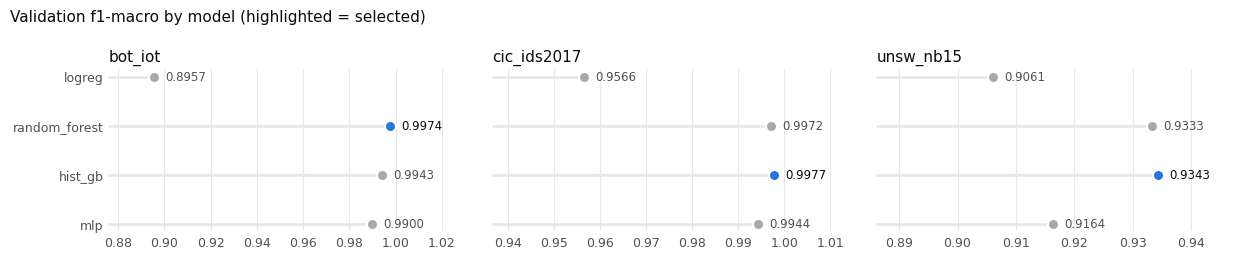

In [ ]:
import matplotlib.pyplot as plt
comp = {m: val_tab.pivot(index="model", columns="dataset", values=m).reindex(list(MODELS)) for m in ["f1_macro", "pr_auc", "mcc", "fpr"]}
rank = val_tab.assign(rank=val_tab.groupby("dataset")[SELECTION_METRIC].rank(ascending=False, method="min")) \
              .pivot(index="model", columns="dataset", values="rank").reindex(list(MODELS))
for m, t in comp.items():
    print(f"\n{m}"); display(t.round(4))
print("\nrank by", SELECTION_METRIC); display(rank.astype(int))
pd.concat({m: t for m, t in comp.items()}, names=["metric"]).to_csv(RES / "model_comparison.csv")

INK, MUTED, GRID, HIGHLIGHT, OTHER = "#0b0b0b", "#52514e", "#e8e7e2", "#2a78d6", "#a9a8a2"
order = list(MODELS)
fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.2 * len(DATASETS), 2.6), sharey=True)
for ax, k in zip(np.atleast_1d(axes), DATASETS):
    vals = np.array([VALROWS[(k, m)][SELECTION_METRIC] for m in order])
    best = int(np.argmax(vals)); lo = max(0.0, vals.min() - 0.02); span = max(vals.max() - lo, 1e-3)
    for i, v in enumerate(vals):
        ax.hlines(i, lo, v, color=GRID, linewidth=2, zorder=1)
        ax.scatter(v, i, s=64, color=HIGHLIGHT if i == best else OTHER, zorder=3, edgecolor="white", linewidth=1.5)
        ax.text(v + 0.04 * span, i, f"{v:.4f}", ha="left", va="center", fontsize=8.5, color=INK if i == best else MUTED)
    ax.set_xlim(lo, vals.max() + 0.3 * span)
    ax.set_yticks(range(len(order))); ax.set_yticklabels(order, color=INK)
    ax.set_title(k, loc="left", fontsize=11, color=INK)
    ax.tick_params(colors=MUTED, labelsize=9, length=0); ax.grid(axis="x", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for s in ax.spines.values(): s.set_visible(False)
    ax.invert_yaxis()
fig.suptitle(f"Validation {SELECTION_METRIC.replace('_', '-')} by model (highlighted = selected)", x=0.01, ha="left", fontsize=11, color=INK)
fig.tight_layout(); fig.savefig(RES / "figures" / "validation_model_comparison.png", dpi=200, bbox_inches="tight"); plt.show()

## 4.9 · Model selection

In [ ]:
SELECTED = {}
for k in DATASETS:
    t = val_tab[val_tab.dataset == k].sort_values([SELECTION_METRIC, "pr_auc", "fit_seconds"], ascending=[False, False, True])
    best = t.iloc[0]
    thr, score = tune_threshold(VAL[k][1], VALPROB[(k, best.model)], SELECTION_METRIC)
    SELECTED[k] = {"model": best.model, "params": MODELS[best.model], "val_" + SELECTION_METRIC: float(best[SELECTION_METRIC]),
                   "val_pr_auc": float(best.pr_auc), "tuned_threshold": thr, "val_" + SELECTION_METRIC + "_at_tuned": score,
                   "runner_up": t.iloc[1].model if len(t) > 1 else None,
                   "margin_over_runner_up": float(best[SELECTION_METRIC] - t.iloc[1][SELECTION_METRIC]) if len(t) > 1 else None}
    print(f"{k:<12} -> {best.model:<14} val {SELECTION_METRIC} {best[SELECTION_METRIC]:.4f} (runner-up {SELECTED[k]['runner_up']}, "
          f"+{SELECTED[k]['margin_over_runner_up']:.4f}) | tuned threshold {thr:.3f} -> {score:.4f}")
(RES / "model_selection.json").write_text(json.dumps(SELECTED, indent=2, default=str))

bot_iot      -> random_forest  val f1_macro 0.9974 (runner-up hist_gb, +0.0031) | tuned threshold 0.660 -> 0.9978
cic_ids2017  -> hist_gb        val f1_macro 0.9977 (runner-up random_forest, +0.0005) | tuned threshold 0.790 -> 0.9980
unsw_nb15    -> hist_gb        val f1_macro 0.9343 (runner-up random_forest, +0.0011) | tuned threshold 0.480 -> 0.9350


1486

## 4.10 · Final model retraining

In [ ]:
FINAL = {}
for k in DATASETS:
    name = SELECTED[k]["model"]
    Xa, ya, ca, _ = load_split(BASE, M3, k, "train"); Xb, yb, cb, _ = VAL[k]
    X = np.concatenate([Xa, Xb]); y = np.concatenate([ya, yb]); c = np.concatenate([ca, cb]); del Xa
    if FINAL_TRAIN_CAP and len(y) > FINAL_TRAIN_CAP:
        keep, _ = train_test_split(np.arange(len(y)), train_size=FINAL_TRAIN_CAP, stratify=_strat(c), random_state=SEED)
        X, y = X[np.sort(keep)], y[np.sort(keep)]
    path = MODEL_DIR / "final" / f"{k}__{name}.joblib"
    model, secs, cached = train_or_load(name, MODELS[name], X, y, path, SEED, FORCE_RETRAIN)
    FINAL[k] = {"model": name, "path": path, "n_train": int(len(y)), "fit_seconds": round(secs, 1), "attack_rate": float(y.mean())}
    print(f"{k:<12} {name:<14} {len(y):>10,} rows  fit {secs:8.1f}s{' (checkpoint)' if cached else ''} -> {path.relative_to(BASE)}")
    del X, y, model; gc.collect()

bot_iot      random_forest     768,333 rows  fit    189.9s (checkpoint) -> models/module4/final/bot_iot__random_forest.joblib
cic_ids2017  hist_gb         1,000,000 rows  fit     58.4s -> models/module4/final/cic_ids2017__hist_gb.joblib
unsw_nb15    hist_gb            99,268 rows  fit     15.9s -> models/module4/final/unsw_nb15__hist_gb.joblib


## 4.11 · Held-out test evaluation

In [ ]:
TEST_ROWS, PERCLASS = [], []
for k in DATASETS:
    model = joblib.load(FINAL[k]["path"])["model"]
    Xte, yte, cte, rte = load_split(BASE, M3, k, "test")
    t0 = time.time(); p = predict_proba1(model, Xte); ps = time.time() - t0
    pd.DataFrame({"row": rte, "y_binary": yte, "y_class": cte, "prob_attack": p}).to_parquet(RES / "test_predictions" / f"{k}.parquet", index=False)
    for label, thr in [("default_0.5", 0.5), ("tuned_on_val", SELECTED[k]["tuned_threshold"])]:
        m = binary_metrics(yte, p, thr); m.update(dataset=k, model=FINAL[k]["model"], threshold_rule=label, predict_seconds=round(ps, 1), n_test=int(len(yte)))
        TEST_ROWS.append(m)
    pc = per_class_detection(cte, yte, p, SELECTED[k]["tuned_threshold"]); pc.insert(0, "dataset", k); PERCLASS.append(pc)
    del model, Xte; gc.collect()
test_tab = pd.DataFrame(TEST_ROWS)[["dataset", "model", "threshold_rule", "threshold", "f1_macro", "f1_attack", "precision_attack",
                                    "recall_attack", "mcc", "roc_auc", "pr_auc", "balanced_accuracy", "accuracy", "fpr", "fnr",
                                    "tp", "fp", "tn", "fn", "n_test", "predict_seconds"]]
test_tab.to_csv(RES / "test_metrics.csv", index=False)
perclass = pd.concat(PERCLASS, ignore_index=True); perclass.to_csv(RES / "test_per_class_detection.csv", index=False)
display(test_tab.style.format({c: "{:.4f}" for c in test_tab.columns[3:15]}).hide(axis="index"))
print("Per-class detection on test (tuned threshold): detection_rate for attack classes, false_alarm_rate for benign")
display(perclass.round(4))

dataset,model,threshold_rule,threshold,f1_macro,f1_attack,precision_attack,recall_attack,mcc,roc_auc,pr_auc,balanced_accuracy,accuracy,fpr,fnr,tp,fp,tn,fn,n_test,predict_seconds
bot_iot,random_forest,default_0.5,0.5000,0.9982,1.0000,1.0000,1.0000,0.9963,1.0000,1.0000,0.9978,0.9999,0.0044,0.0000,134214,6,1365,4,135589,0.500000
bot_iot,random_forest,tuned_on_val,0.6600,0.9978,1.0000,1.0000,0.9999,0.9956,1.0000,1.0000,0.9992,0.9999,0.0015,0.0001,134208,2,1369,10,135589,0.500000
cic_ids2017,hist_gb,default_0.5,0.5000,0.9979,0.9965,0.9936,0.9993,0.9958,0.9999,0.9988,0.9991,0.9989,0.0012,0.0007,50394,323,279039,34,329790,4.500000
cic_ids2017,hist_gb,tuned_on_val,0.7900,0.9985,0.9974,0.9973,0.9974,0.9969,0.9999,0.9988,0.9985,0.9992,0.0005,0.0026,50299,135,279227,129,329790,4.500000
unsw_nb15,hist_gb,default_0.5,0.5000,0.8590,0.8888,0.8147,0.9777,0.7409,0.9775,0.9831,0.8526,0.8653,0.2725,0.0223,44322,10083,26917,1010,82332,1.700000
unsw_nb15,hist_gb,tuned_on_val,0.4800,0.8544,0.8861,0.8089,0.9795,0.7345,0.9775,0.9831,0.8480,0.8613,0.2835,0.0205,44404,10490,26510,928,82332,1.700000


Per-class detection on test (tuned threshold): detection_rate for attack classes, false_alarm_rate for benign


,dataset,y_class,rows,is_attack,detection_rate,false_alarm_rate
0,bot_iot,benign,1371,0,NaN,0.0015
1,bot_iot,ddos,44842,1,1.0000,NaN
2,bot_iot,dos,44743,1,1.0000,NaN
3,bot_iot,reconnaissance,44395,1,1.0000,NaN
4,bot_iot,theft,238,1,0.9748,NaN
5,cic_ids2017,benign,279362,0,NaN,0.0005
6,cic_ids2017,bot,210,1,0.6667,NaN
7,cic_ids2017,ddos,19202,1,0.9995,NaN
8,cic_ids2017,dos_goldeneye,1543,1,1.0000,NaN
9,cic_ids2017,dos_hulk,25903,1,0.9993,NaN


## 4.12 · Final performance summary

In [ ]:
lines = ["# Module 4 — Classical ML results", "",
         f"Binary detection (benign vs attack). Models compared on validation after training on a stratified {DEV_TRAIN_CAP:,}-row subsample of train; "
         f"the selected model is retrained on train + val (cap {FINAL_TRAIN_CAP:,}) and evaluated once on test. Seed {SEED}.", "",
         "## Validation (model comparison)", "", "| Dataset | " + " | ".join(MODELS) + " |", "|---|" + "---|" * len(MODELS)]
for k in DATASETS:
    lines.append(f"| {k} | " + " | ".join(f"{VALROWS[(k, m)][SELECTION_METRIC]:.4f}" for m in MODELS) + " |")
lines += ["", f"Values are validation {SELECTION_METRIC}.", "", "## Held-out test (selected model)", "",
          "| Dataset | Model | Threshold | Macro-F1 | Attack F1 | Precision | Recall | MCC | ROC-AUC | PR-AUC | FPR | FNR |",
          "|---|---|---|---|---|---|---|---|---|---|---|---|"]
for _, r in test_tab.iterrows():
    lines.append(f"| {r.dataset} | {r.model} | {r.threshold:.3f} | {r.f1_macro:.4f} | {r.f1_attack:.4f} | {r.precision_attack:.4f} | "
                 f"{r.recall_attack:.4f} | {r.mcc:.4f} | {r.roc_auc:.4f} | {r.pr_auc:.4f} | {r.fpr:.4f} | {r.fnr:.4f} |")
weak = perclass[(perclass.detection_rate < 0.9)]
lines += ["", "## Attack classes detected below 90% on test (tuned threshold)", ""]
lines += [f"- {r.dataset} / {r.y_class}: {r.detection_rate:.3f} of {r.rows:,} rows" for _, r in weak.iterrows()] or ["- none"]
(RES / "summary.md").write_text("\n".join(lines))
manifest = {"created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"), "module": "4 - classical ML",
            "module3_manifest_created": M3["created_utc"], "selection": SELECTED,
            "final_models": {k: {**{kk: vv for kk, vv in v.items() if kk != "path"}, "path": str(v["path"].relative_to(BASE)),
                                 "sha256": sha256_file(v["path"])} for k, v in FINAL.items()},
            "environment": {"python": sys.version.split()[0], "sklearn": sklearn.__version__, "cpus": os.cpu_count(), "platform": platform.platform()}}
(RES / "module4_manifest.json").write_text(json.dumps(manifest, indent=2, default=str))
print("\n".join(lines))

# Module 4 — Classical ML results

Binary detection (benign vs attack). Models compared on validation after training on a stratified 300,000-row subsample of train; the selected model is retrained on train + val (cap 1,000,000) and evaluated once on test. Seed 42.

## Validation (model comparison)

| Dataset | logreg | random_forest | hist_gb | mlp |
|---|---|---|---|---|
| bot_iot | 0.8957 | 0.9974 | 0.9943 | 0.9900 |
| cic_ids2017 | 0.9566 | 0.9972 | 0.9977 | 0.9944 |
| unsw_nb15 | 0.9061 | 0.9333 | 0.9343 | 0.9164 |

Values are validation f1_macro.

## Held-out test (selected model)

| Dataset | Model | Threshold | Macro-F1 | Attack F1 | Precision | Recall | MCC | ROC-AUC | PR-AUC | FPR | FNR |
|---|---|---|---|---|---|---|---|---|---|---|---|
| bot_iot | random_forest | 0.500 | 0.9982 | 1.0000 | 1.0000 | 1.0000 | 0.9963 | 1.0000 | 1.0000 | 0.0044 | 0.0000 |
| bot_iot | random_forest | 0.660 | 0.9978 | 1.0000 | 1.0000 | 0.9999 | 0.9956 | 1.0000 | 1.0000 | 0.0015 | 0.0001 |
| cic_ids